# Нейросеть для предсказания калорийности блюд

## Информация о проекте

**Задача** - Создать и обучить нейросеть, которая будет предсказывать калорийность блюд.

**Цель** - Получить DL-модель, способную оценить калорийность блюда.

**Целевая метрика** - Модель считается готовой к интеграции в продукт при точности оценки MAE < 50 (MAE — Mean Absolute Error) на тестовой выборке.

**Датасет** - Содержит фотографии блюд, описание ингредиентов, а также общую массу порции и калорийность.

`data/ingredients.csv`
- id — ID ингредиента.
- ingr — название ингредиента.

`data/dish.csv`
- dish_id — ID блюда.
- total_calories — общее число калорий. Это целевая переменная.
- total_mass — масса блюда.
- ingredients — список всех ID ингредиентов в формате ingr_0000000122;ingr_0000000026;.., где ненулевая часть соответствует ID ингредиента из data/ingredients.csv.
- split — метка, указывающая, куда отнести блюдо: train/test. Эта метка поможет разделить датасет при тренировке.

`data/images` — датасет с фотографиями блюд, каждая директория соответствует dish_id из data/dish.csv и содержит rgb.png фото блюда.

## Импорты

In [4]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image
from scripts.config import conf
import math
import torch

from scripts.utils import train_model, test_model
from scripts.dataset import preprocess, prepare_dataloader

## Исследовательский анализ данных (EDA)

### Загрузка и первичный осмотр датасетов

In [5]:
df_dish = pd.read_csv(conf.DF_DISH_PATH)
df_ingr = pd.read_csv(conf.DF_INGREDIENTS_PATH)

In [6]:
print("Первые 5 строк датасета `dish.csv`:")
display(df_dish.head())

print("\nПервые 5 строк датасета `ingredients.csv`:")
display(df_ingr.head())

Первые 5 строк датасета `dish.csv`:


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train



Первые 5 строк датасета `ingredients.csv`:


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


In [7]:
print(f"Количество пропусков в датасетах: {df_dish.isna().sum().sum() + df_ingr.isna().sum().sum()}")

Количество пропусков в датасетах: 0


### Анализ текстовых признаков

Объединим таблицы `dish.csv` и `ingredients.csv`: в колонку 'ingredients' датасета `dish.csv` перенесем ингредиенты, проиндексированные в датасете `ingredients.csv`

In [8]:
id_to_word = dict(zip(df_ingr["id"], df_ingr["ingr"]))

def move_ingredients(ingredients):
    ingredients = [int(re.sub("ingr_", "", i)) for i in ingredients.split(";")]
    ingredients = [id_to_word[i] for i in ingredients]
    return " ".join(ingredients)

df_dish["ingredients"] = df_dish["ingredients"].apply(move_ingredients)
df_dish.head()

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,soy sauce garlic white rice parsley onions bro...,test
1,dish_1561662054,419.438782,292.0,pepper white rice mixed greens garlic soy sauc...,train
2,dish_1562008979,382.936646,290.0,jalapenos lemon juice pork wheat berry cabbage...,test
3,dish_1560455030,20.590000,103.0,cherry tomatoes cucumbers baby carrots,train
4,dish_1558372433,74.360001,143.0,deprecated,train


В датасете присутствует ингредиент под названием `deprecated`, который, вероятно, обозначает устаревшую или более недоступную запись в исходном справочнике ингредиентов. Наличие такого значения может свидетельствовать о проблемах качества или актуальности исходного справочника и требует дополнительной обработки. Рассмотрим блюда, в составе которых находится данный ингредиент и выведем их количество:

In [9]:
mask = df_dish["ingredients"].str.contains("deprecated", na=False)

print(f"Количество блюд с ингредиентом под названием 'deprecated': {mask.sum()}")

print("Примеры блюд с ингредиентом 'deprecated':")
display(df_dish.loc[mask, ["dish_id", "ingredients", "total_mass", "total_calories"]][:10])

Количество блюд с ингредиентом под названием 'deprecated': 31
Примеры блюд с ингредиентом 'deprecated':


,dish_id,ingredients,total_mass,total_calories
4,dish_1558372433,deprecated,143.0,74.360001
55,dish_1558114086,deprecated,143.0,74.360001
123,dish_1558027001,deprecated,68.0,20.400002
334,dish_1558373159,sausage deprecated almonds,334.0,1013.337036
594,dish_1558115364,potatoes deprecated almonds bacon,313.0,485.260010
701,dish_1558114875,deprecated,143.0,74.360001
749,dish_1558375506,deprecated,142.0,73.839996
908,dish_1558028142,deprecated,73.0,21.900002
1025,dish_1558031019,yam bacon deprecated honeydew melons,197.0,206.442001
1068,dish_1558030724,deprecated,61.0,18.300001


In [10]:
deprecated_only = df_dish[df_dish['ingredients'] == 'deprecated']
print(f"Количество блюд, у которых 1 ингредиент - `deprecated`: {len(deprecated_only)}")

Количество блюд, у которых 1 ингредиент - `deprecated`: 16


Из 31 блюд, содержащих данный ингредиент, 16 состоят только лишь из него. Рассмотрим эти блюда на картинках

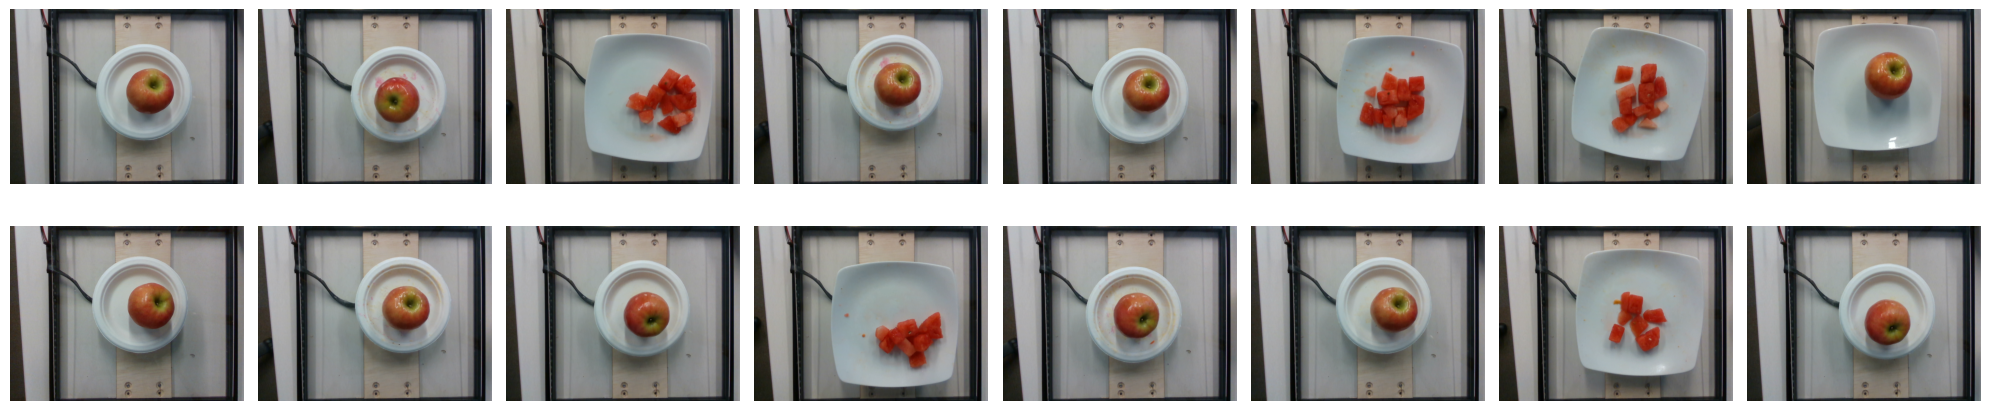

In [11]:
def plot_images(paths, max_cols=8, figsize_per_img=2.5):
    num_imgs = len(paths)

    ncols = min(num_imgs, max_cols)
    nrows = math.ceil(num_imgs / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * figsize_per_img, nrows * figsize_per_img)
    )

    axes = np.array(axes).reshape(-1)

    for i, path in enumerate(paths):
        img = Image.open(
            f"{conf.IMAGE_ROOT}/{path}/{conf.IMAGE_NAME}"
        )
        axes[i].imshow(img)
        axes[i].axis("off")

    # Если последняя строка заполнена не полностью - убираем лишние axes
    for i in range(num_imgs, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

plot_images(deprecated_only["dish_id"].tolist())

Визуальная проверка показала, что соответствующие изображения содержат реальные блюда, а именно яблоко и, предположительно, нарезанный арбуз. Тем не менее невозможно определить однозначно, арбуз это или какой-то другой фрукт, а также то, эти ли ингредиенты содержаться в составе более сложных блюд. Таким образом, поскольку значение deprecated не позволяет получить информацию об ингредиентном составе, а восстановление ингредиентов по изображениям потребовало бы дополнительной ручной разметки, такие записи мы исключаем из набора данных.

In [12]:
df_dish["ingredients"] = (
    df_dish["ingredients"]
    .str.replace(r"\bdeprecated\b", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df_dish = df_dish[df_dish["ingredients"].ne("")].reset_index(drop=True)

Разделим выборки на тренировочную и тестовую:

In [13]:
df_train = df_dish[df_dish["split"] == "train"].drop(columns="split").reset_index(drop=True)
df_test = df_dish[df_dish["split"] == "test"].drop(columns="split").reset_index(drop=True)

### Анализ визуальных признаков

Рассмотрим возможную ширину и высоту фотографий датасета:

In [14]:
widths = []
heights = []

for path in df_dish["dish_id"]:
    image_path = f"{conf.IMAGE_ROOT}/{path}/{conf.IMAGE_NAME}"
    with Image.open(image_path) as img:
        widths.append(img.width)
        heights.append(img.height)

print("Ширина фотографий:")
display(pd.Series(widths).describe())

print("\nВысота фотографий:")
display(pd.Series(heights).describe())

Ширина фотографий:


count    3246.0
mean      640.0
std         0.0
min       640.0
25%       640.0
50%       640.0
75%       640.0
max       640.0
dtype: float64


Высота фотографий:


count    3246.0
mean      480.0
std         0.0
min       480.0
25%       480.0
50%       480.0
75%       480.0
max       480.0
dtype: float64

Все фотографии датасета - одного размера. Рассмотрим примеры случайных фотографий и их тестового описания в датасете:

Тренировочный датасет:
Количество блюд: 2743


,dish_id,total_calories,total_mass,ingredients
1854,dish_1558721904,74.360001,143.0,apple
2596,dish_1558629444,225.459000,39.0,almonds
1947,dish_1559934708,202.445465,178.0,garlic quinoa salt mushroom olive oil chicken ...
559,dish_1559320019,196.820007,205.0,pineapple sweet potato bacon berries
1804,dish_1561579933,447.449249,306.0,salt cucumbers olive oil basil onions bell pep...
2398,dish_1565897680,770.448853,405.0,olive oil wheat berry mustard mixed greens gar...
2575,dish_1558630006,51.750000,75.0,grapes


Примеры блюд в картинках:


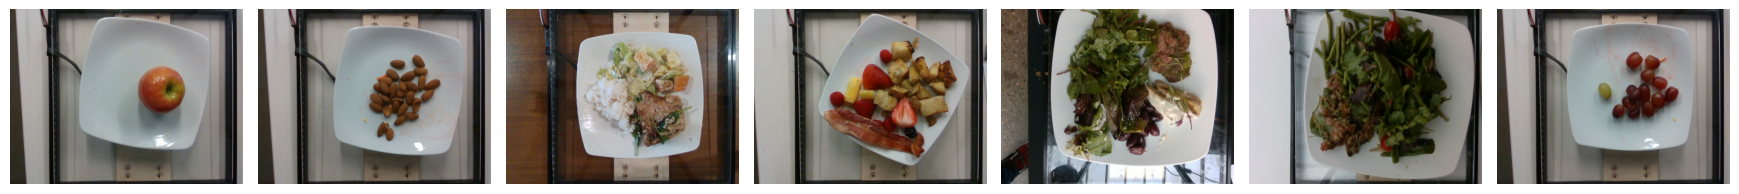


Тестовый датасет:
Количество блюд: 503


,dish_id,total_calories,total_mass,ingredients
1451,dish_1565727921,768.554016,397.0,black beans chicken olives olive oil broccoli ...
2595,dish_1565812116,44.440170,36.0,mustard salt olive oil blueberries vinegar aru...
226,dish_1563305883,83.052505,77.0,olive oil spinach (raw) parmesan cheese crouto...
2275,dish_1558114609,540.898010,160.0,grapes sausage almonds bacon
825,dish_1563911255,293.192169,235.0,fried rice salt rosemary lemon juice olive oil...
1988,dish_1561579902,406.397736,247.0,olive oil rosemary lemon juice butter pepper c...
2624,dish_1563207332,288.570007,241.0,scrambled eggs yam egg whites olive oil sweet ...


Примеры блюд в картинках:


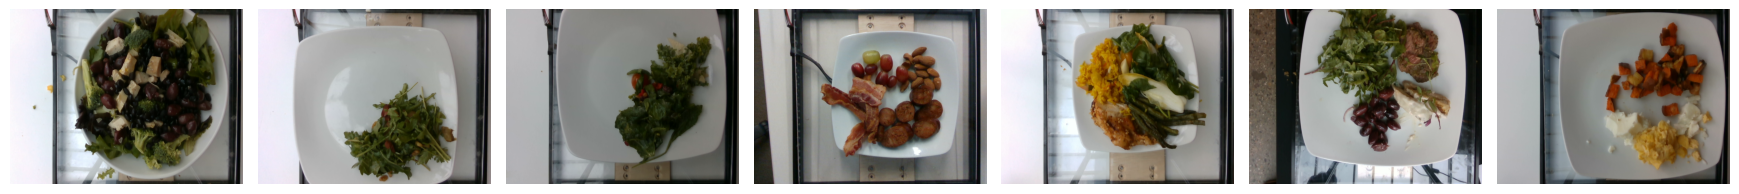

In [15]:
random_imgs_train = df_train.sample(7)
random_imgs_test = df_train.sample(7)

print("Тренировочный датасет:")
print(f"Количество блюд: {len(df_train)}")
display(random_imgs_train)
print("Примеры блюд в картинках:")
plot_images(random_imgs_train["dish_id"].tolist())

print("\nТестовый датасет:")
print(f"Количество блюд: {len(df_test)}")
display(random_imgs_test)
print("Примеры блюд в картинках:")
plot_images(random_imgs_test["dish_id"].tolist())

- **Ракурс съемки блюд немного варьируется** - полезно будет сделать аугментацию, которая поворачивает изображение.
- **Масштаб объектов в кадре отличается** - где-то блюдо занимает практически все пространство, а на каких-то фотографиях присутствует много окружающего пространства. Поэтому в аугментации можно добавить небольшую случайную обрезку - так модель будет меньше зависеть от конкретного масштаба и композиции.
- **Освящение на фото слегка различается** - поэтому уместно добавить небольшую коррекцию яркости/насыщенности.

### Анализ числовых признаков

In [16]:
train_dish_mass = df_train["total_mass"]
test_dish_mass = df_test["total_mass"]

print("Масса блюд в тренировочном датасете:")
display(train_dish_mass.describe())

print("Масса блюд в тестовом датасете:")
display(test_dish_mass.describe())

Масса блюд в тренировочном датасете:


count    2743.000000
mean      218.450237
std       163.293077
min         5.000000
25%        94.500000
50%       180.000000
75%       308.000000
max      3051.000000
Name: total_mass, dtype: float64

Масса блюд в тестовом датасете:


count    503.000000
mean     199.155070
std      152.030519
min        1.000000
25%       82.500000
50%      161.000000
75%      280.500000
max      871.000000
Name: total_mass, dtype: float64

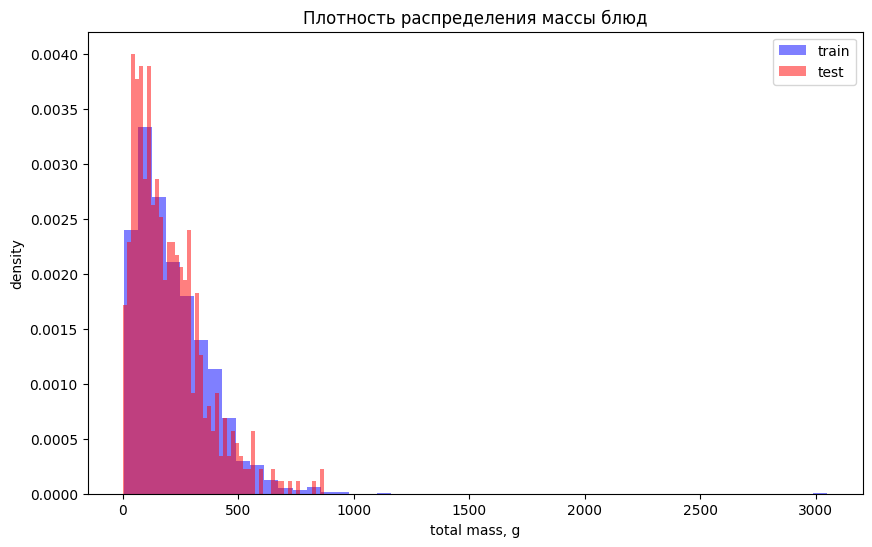

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(train_dish_mass, bins=50, density=True, alpha=0.5, color="blue", label="train")
plt.hist(test_dish_mass, bins=50, density=True, alpha=0.5, color="red", label="test")

plt.title("Плотность распределения массы блюд")
plt.legend()
plt.xlabel("total mass, g")
plt.ylabel("density")

plt.show()

- распределения массы блюд в train и test выборках довольно похожи
- обе выборки имеют выраженную правостороннюю асимметрию
- основная масса блюд находится примерно в диапазоне 0–500г
- после ~500г наблюдается длинный хвост
- есть отдельные очень большие значения - вплоть до ~3000г

Рассмотрим подробнее датасеты на предмет выбросов:

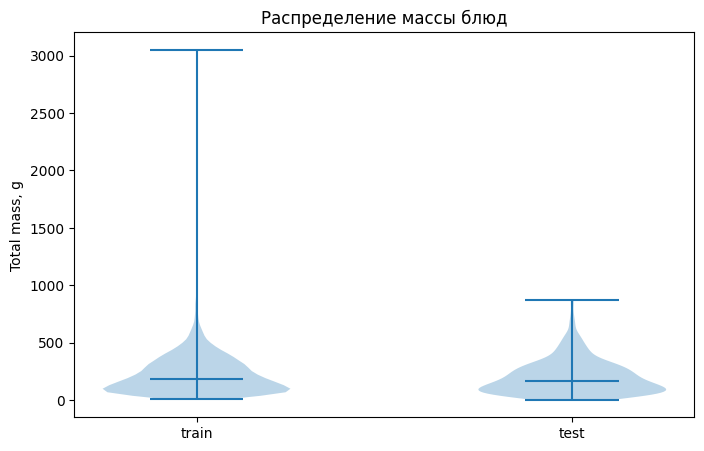

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.violinplot(
    [train_dish_mass, test_dish_mass],
    positions=[1, 2],
    showmedians=True
)

ax.set_xticks([1, 2])
ax.set_xticklabels(["train", "test"])
ax.set_ylabel("Total mass, g")
ax.set_title("Распределение массы блюд")

plt.show()

В тренировочном датасете наблюдаются экстремальные выбросы. Посмотрим, что это за блюда

In [19]:
df_train.nlargest(5, "total_mass")[
    ["dish_id", "ingredients", "total_mass", "total_calories"]
]

,dish_id,ingredients,total_mass,total_calories
1278,dish_1560974769,spinach (raw) tortilla chips corn cheese white...,3051.0,3943.325195
272,dish_1561739805,raspberries broccoli berries sweet potato scra...,1102.0,696.363525
1948,dish_1564590352,pineapple cantaloupe salsa watermelon olive oi...,962.0,497.915833
2530,dish_1561739760,vinaigrette granola blackberries berries mixed...,937.0,452.163513
2382,dish_1563305083,chili lettuce shallots broccoli olive oil pars...,901.0,1234.856323


Все выглядит правдоподобно, поэтому вероятность ошибки исключена

### Анализ целевой переменной

In [20]:
print(f"TRAIN:")
display(df_train["total_calories"].describe())

print(f"TEST:")
display(df_test["total_calories"].describe())

TRAIN:


count    2743.000000
mean      255.798125
std       221.093759
min         0.000000
25%        83.717881
50%       208.746002
75%       376.869660
max      3943.325195
Name: total_calories, dtype: float64

TEST:


count     503.000000
mean      257.031679
std       212.341310
min         0.000000
25%        75.269627
50%       229.979980
75%       370.713456
max      1050.511108
Name: total_calories, dtype: float64

В датасете присутствуют пустые тарелки с 0 калорийностью. Рассмотрим, что это за блюда:

TRAIN блюда с 0 калорийностью: 


,dish_id,total_calories,total_mass,ingredients
2219,dish_1556575700,0.0,86.0,plate only



TEST блюда с 0 калорийностью: 


,dish_id,total_calories,total_mass,ingredients
44,dish_1557861216,0.0,1.0,plate only



Фотографии блюд с 0 калорийностью: 


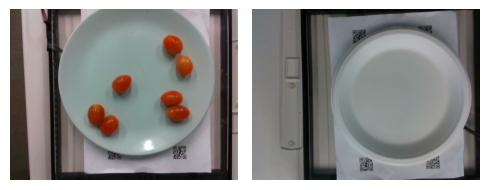

In [21]:
print("TRAIN блюда с 0 калорийностью: ")
display(df_train[df_train["total_calories"] == 0.0])

print("\nTEST блюда с 0 калорийностью: ")
display(df_test[df_test["total_calories"] == 0.0])

print("\nФотографии блюд с 0 калорийностью: ")
train_photo_zero_kcal = df_train.loc[df_train["total_calories"] == 0.0, "dish_id"].tolist()
test_photo_zero_kcal = df_test.loc[df_test["total_calories"] == 0.0, "dish_id"].tolist()

plot_images(train_photo_zero_kcal + test_photo_zero_kcal)

Предсказание калорийности пустых тарелок не соответствует нашей задаче, поэтому удалим такие наблюдения:

In [22]:
df_train = df_train[df_train["total_calories"] != 0.0].reset_index(drop=True)
df_test = df_test[df_test["total_calories"] != 0.0].reset_index(drop=True)

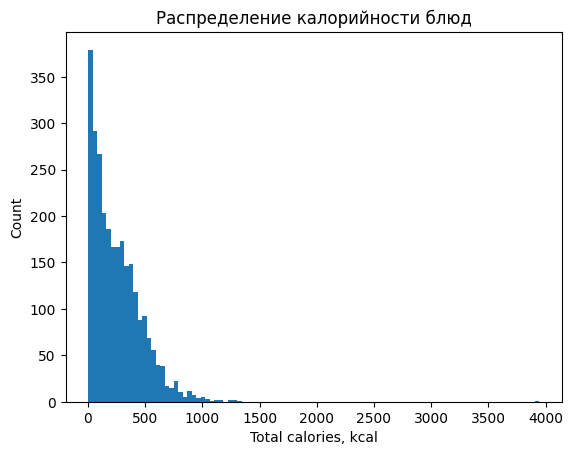

In [23]:
plt.hist(df_train["total_calories"], bins=100)
plt.xlabel("Total calories, kcal")
plt.ylabel("Count")
plt.title("Распределение калорийности блюд")

plt.show()

- распределение калорийности блюд имеет выраженную правостороннюю ассиметрию.
- основная масса блюд имеет калорийность от 0 до 500 ккал.
- имеются также экстремальные выбросы, достигающие ~4000 ккал на блюдо.

Рассмотрим, как зависит калорийность блюда от его массы:

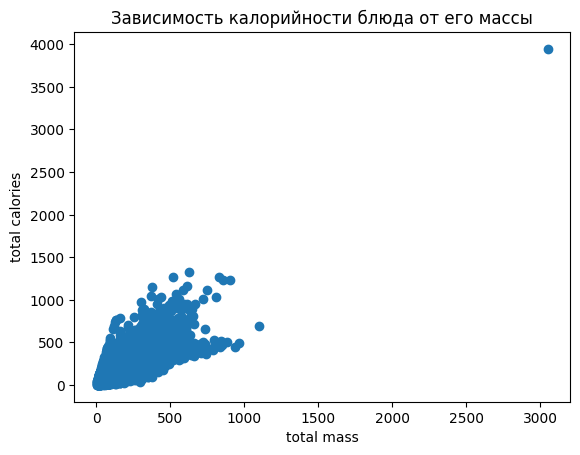

In [24]:
plt.scatter(
    df_train["total_mass"],
    df_train["total_calories"],
)
plt.title("Зависимость калорийности блюда от его массы")
plt.xlabel("total mass")
plt.ylabel("total calories")
plt.show()

График демонстрирует, что **есть выраженная положительная зависимость массы от калорийности**
- В целом с увеличением массы блюда увеличивается и его калорийность. Это ожидаемо, поскольку более крупная порция обычно содержит больше еды и, соответственно, калорий

**Связь не линейная и разброс довольно большой**
- Для одной и той же массы калорийность может сильно различаться. Например, блюда массой около 500г имеют очень разную калорийность. Это логично, потому что 500г салата и 500г орехов имеют совершенно разную энергетическую ценность

Ввиду второго наблюдения становится ясно, что одного признака о весе блюда было бы недостаточно для корректного предсказания его калорийности.

### Вывод по EDA

- В данных представлены три типа признаков: числовые (масса блюда в граммах), текстовые (описание ингредиентного состава) и визуальные (фотографии блюд). Для решения задачи будут использованы предобученные модели для извлечения эмбеддингов из текстовых и визуальных данных. Числовой признак массы будет предварительно нормализован и преобразован в компактное векторное представление с помощью небольшого полносвязного слоя. Полученные представления всех трех модальностей будут объединены в единый вектор и переданы в регрессионную модель для предсказания калорийности блюда.
- Визуальные данные будут предварительно аугментированы с помощью следующих трансформаций: изменения яркости и контрастности, поворота изображения и горизонтального отражения. Изменение цветовых характеристик изображений применяться не будет, поскольку цвет является значимым визуальным признаком при идентификации ингредиентов блюда.
- Качество предсказаний модели будет оцениваться с помощью метрики MAE (Mean Absolute Error), которая измеряет среднюю абсолютную ошибку предсказаний в единицах целевой переменной, что делает данную метрику легко интерпретируемой.

## Обучение модели

In [25]:
device = "cuda" if torch.cuda.is_available() else "cpu"

train_history, best_model = train_model(conf, device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Epoch 28/30 | train_loss: 36.6553 |  train_mae: 36.66 | val_loss: 43.2355 | val_mae: 43.46


  0%|          | 0/549 [00:00<?, ?it/s]

Epoch 29/30 | train_loss: 35.5889 |  train_mae: 35.62 | val_loss: 40.6764 | val_mae: 40.89


  0%|          | 0/549 [00:00<?, ?it/s]

Epoch 30/30 | train_loss: 35.7424 |  train_mae: 35.74 | val_loss: 36.0613 | val_mae: 36.26
New best model, epoch: 30


### График функции потерь на обучении и валидации

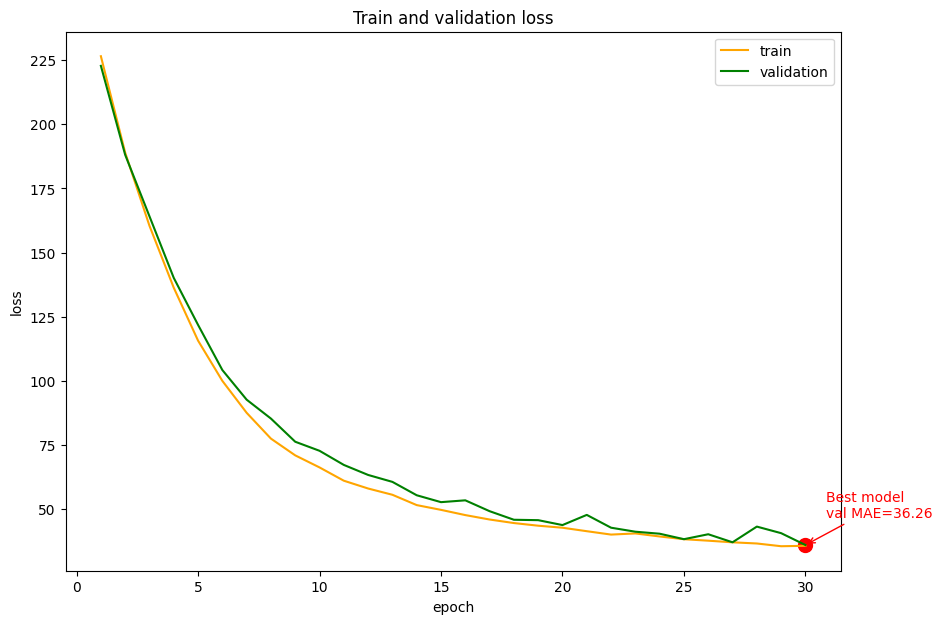

In [26]:
plt.figure(figsize=(10, 7))

epochs = [item["epoch"] for item in train_history]
train_loss = [item["train_loss"] for item in train_history]
val_loss = [item["val_loss"] for item in train_history]
val_mae = [item["val_mae"] for item in train_history]

arg_best_mae = np.argmin(val_mae)
best_epoch = epochs[arg_best_mae]
best_val_mae = val_mae[arg_best_mae]
best_val_loss = val_loss[arg_best_mae]

plt.plot(epochs, train_loss, color="orange", label="train")
plt.plot(epochs, val_loss, color="green", label="validation")

plt.scatter(best_epoch, best_val_loss, color="red", s=100)
plt.annotate(
    f"Best model\nval MAE={best_val_mae:.2f}",
    xy=(best_epoch, best_val_loss),
    xytext=(15, 20),
    color="red",
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="red")
  )

plt.legend()
plt.title("Train and validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

Обучение прошло стабильно - кривая функции потерь плавно уменьшается на протяжении всех 30 эпох обучения без резких скачков. Признаков переобучения нет, минимума по ошибкам и метрике MAE на валидации модель достигает на 30-ой эпохе, val MAE = 36.26. Поэтому для финального предсказания на тестовых данных будет использовано состояние модели на момент 30-ой эпохи.

## Инференс на тестовых данных

In [28]:
test_mae, results_df = test_model(conf, best_model, device)

In [29]:
print(f"Test MAE: {test_mae:.2f}")

Test MAE: 44.01


### Анализ ошибок модели

Построим гистограммы распределений предсказаний и реальных меток

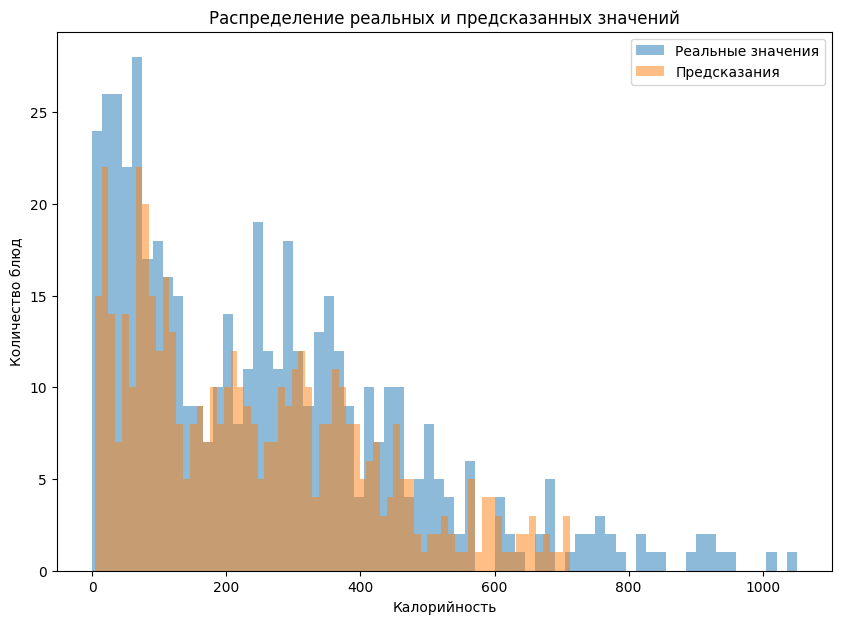

In [31]:
plt.figure(figsize=(10, 7))

plt.hist(results_df["y_true"], bins=70, alpha=0.5, label="Реальные значения")
plt.hist(results_df["y_preds"], bins=70, alpha=0.5, label="Предсказания")

plt.xlabel("Калорийность")
plt.ylabel("Количество блюд")
plt.title("Распределение реальных и предсказанных значений")
plt.legend()
plt.show()

Распределения в целом похожи: предсказанные значения (оранжевая гистограмма) в целом повторяют форму реальных (синяя гистограмма). Это говорит о том, что модель уловила общую структуру распределения калорийности блюд. 

Однако исходя из гистограммы, модель хуже вопроизводит распределение в области высоких значений: реальные значения калорийности достигают 1000 ккал, тогда как предсказанные в области после ~700 ккал отсутствуют вовсе или практически. Это может означать, что модель склонна недооценивать калорийность высококалорийных блюд. 

Построим диаграмму рассеяния реальных и предсказанных значений калорийности блюд. По оси X отложим реальные значения калорийности, а по оси Y - предсказания модели. Красная пунктирная линия (y=x) соответствует идеальным предсказаниям, при которых предсказанная калорийность совпадает с реальной. Чем ближе точки к этой линии, тем точнее предсказания модели

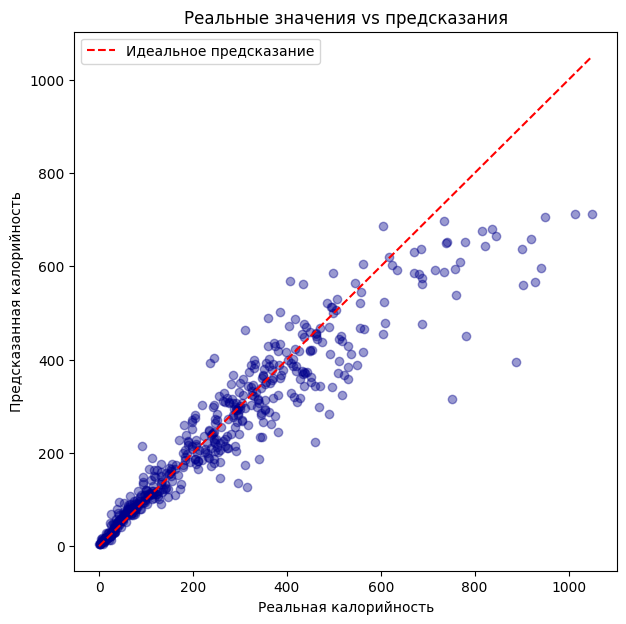

In [33]:
plt.figure(figsize=(7, 7))

plt.scatter(results_df["y_true"], results_df["y_preds"], color="darkblue", alpha=0.4)

min_val = min(results_df["y_true"].min(), results_df["y_preds"].min())
max_val = max(results_df["y_true"].max(), results_df["y_preds"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="red",
    label="Идеальное предсказание"
)

plt.xlabel("Реальная калорийность")
plt.ylabel("Предсказанная калорийность")
plt.title("Реальные значения vs предсказания")
plt.legend()
plt.show()

График демонстрирует выраженную тенденции модели к недооценке в области высоких значений. Рассмотрим подробнее:

В области низкой калорийности точки расположены достаточно близко к диагонали, что свидетельствует о сравнительно точных предсказаниях для таких блюд. С увеличением калорийности разброс точек относительно диагонали возрастает и ошибки модели становятся более выраженными. При реальных значениях выше 600 ккал предсказанные значения находятся практически все под дигональю - то есть блюда с калорийностью выше 600 преимущественно недооцениваются.

Рассмотрим топ-5 блюд с максимальной абсолютной ошибкой:

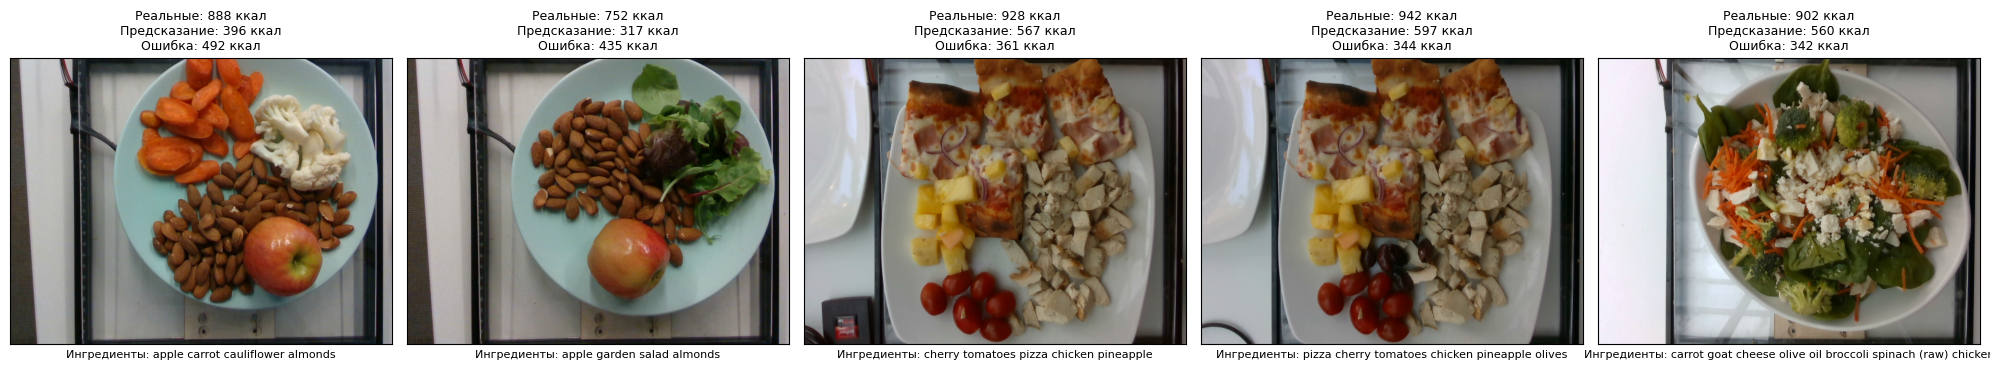

In [34]:
top5 = results_df.nlargest(5, "error")

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, dish_id, ingredients, y_true, y_pred, error in zip(
    axes,
    top5["dish_id"],
    top5["ingredients"],
    top5["y_true"],
    top5["y_preds"],
    top5["error"],
):
    image_path = (
        f"{conf.IMAGE_ROOT}/{dish_id}/{conf.IMAGE_NAME}"
    )

    with Image.open(image_path) as img:
        ax.imshow(img.copy())

    ax.set_title(
        f"Реальные: {y_true:.0f} ккал\n"
        f"Предсказание: {y_pred:.0f} ккал\n"
        f"Ошибка: {error:.0f} ккал",
        fontsize=9,
    )

    ax.set_xlabel(f"Ингредиенты: {ingredients}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

Самые большие ошибки модели приходятся на высококалорийные блюда, калорийность которых лежит в диапазоне от 700 до 1000 ккал. Модель склонна недооценивать эти значения, занижая их на 300-500 ккал.

Два примера из 5 рассматриваемых содержат орехи.  Третий и четвертое блюда - практически идентичны. Причина ошибок модели на этих 5 блюдах может заключаться в недостаточной представленности подобных блюд в обучающей выборке. Несмотря на то что модель использует информацию об ингредиентах, изображение блюда и его общую массу, ей могло не хватить примеров для корректного усвоения связи между, например, наличием орехов и высокой энергетической ценностью блюда. Поскольку орехи обладают высокой энергетической плотностью, даже небольшое их количество может существенно влиять на общую калорийность. 

## Вывод и рекомендации

Обученная мультимодальная регрессионная модель на тестовых данных показала результат MAE=44, то есть в среднем ошибается на 44 ккал, что является достаточным для интеграции в продукт. Однако анализ ошибок модели показал, что она склонна достаточно сильно недооценивать калорийность высококалорийных блюд (на 300-500 ккал), что объясняется намного меньшей долью представленности блюд такого типа в обучающем датасете. Таким образом, для дальнейшего повышения качества модели рекомендуется увеличить число высококалорийных блюд в обучающем датасете. 